In [1]:
import numpy as np
from scipy.signal.windows import blackmanharris
from rich.progress import track
import os
import glob
from scipy.signal import welch
from scipy.signal import csd
from astropy.time import Time
import astropy.units as u
import astropy.constants as c
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
import matplotlib.pyplot as plt
import datetime

from helpers import pixel_brightness, make_image

In [ ]:
num_antennas = 9
simulate_antennas = True

target_freq = 1420.4*u.MHz
central_freq = target_freq - 4*u.MHz
n_channels = 2**11
samp_rate = 10*u.MHz

# observation coordinates and time
LAT = +52.168638*u.deg
LONG = +4.45827*u.deg
ELEV = 30*u.m 
DATE = datetime.date(2026,10,30)
TIME = datetime.time(16,30,00)
leiden = EarthLocation(lat=LAT, lon=LONG, height=ELEV)
obs_times = datetime.datetime.combine(DATE,TIME)

# pointing direction
az = 0.1 * u.deg
alt = 90 * u.deg #zenith

# built for glob not regex
DATE_STR = str(DATE).replace('-','')
TIME_STR = str(TIME).replace(':','')
DT_PATTERN = rf"{DATE_STR}T{TIME_STR}Z"

FOLDER_NOMENCLATURE = f'./data/obs/' # DT pattern gets handled automatically
FILE_NOMENCLATURE = 'antenna_*.bin'

# import array config from simulation notebook
%store -r largest_baseline
%store -r uv
%store -r pos

# set how many fft blocks to run
num_blocks = 1000

In [3]:
if simulate_antennas:
    n_real_ant = 2
else:
    n_real_ant = num_antennas

CWD = os.getcwd()
files = glob.glob(os.path.join(FOLDER_NOMENCLATURE, DT_PATTERN, FILE_NOMENCLATURE))
print(files)
data = np.zeros((num_antennas, n_channels*num_blocks), dtype=np.complex64)
for i in range(n_real_ant):
    mmap = np.memmap(files[i], dtype=np.complex64, mode='r')
    data[i, :] = mmap[:n_channels*num_blocks]

['./data/obs/20261030T163000Z/antenna_1.bin', './data/obs/20261030T163000Z/antenna_2.bin']


In [4]:
# simulate antennas
if simulate_antennas:
    altaz_frame = AltAz(obstime=obs_times, location=leiden)
    altaz_coords = SkyCoord(alt=alt, az=az, frame=altaz_frame)
    radec_coords = altaz_coords.transform_to('icrs')

    freq = np.sort(np.fft.fftfreq(n_channels, 1/(samp_rate))) + central_freq
    simfreqs = np.tile(freq, num_blocks)
    ra = radec_coords.ra.deg
    dec = radec_coords.dec.deg
    s = np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])
    for k in range(n_real_ant, num_antennas):
        b = pos[k] - pos[0]
        tau = np.dot(b, s)/c.c
        phase_shift = np.exp(-2j * np.pi * simfreqs * tau)
        data[k, :] = data[0, :]*phase_shift

In [5]:
window = blackmanharris(n_channels)
freq = np.zeros(n_channels*num_blocks)
fft_data = np.zeros((num_antennas, n_channels), dtype='complex64')

# Calculate FFTs
for i in track(range(num_antennas), description="Computing FFTs for each antenna"):
    df = data[i, :]
    df = df - np.mean(df)
    frequency, fft_output = welch(df, fs=samp_rate, window=window, nperseg=n_channels, return_onesided=False)
    freq = np.fft.fftshift(frequency) + central_freq
    fft_data[i, :] = np.fft.fftshift(fft_output)


Output()

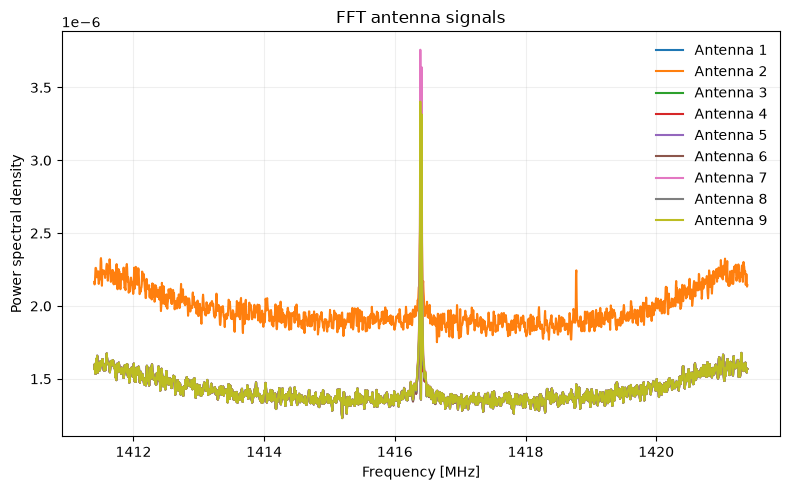

In [6]:
# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
for antenna in range(num_antennas):
    ax.plot(freq, np.real(fft_data[antenna, :]), label=f'Antenna {antenna+1}')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [7]:
subband = int(((target_freq.value - (central_freq.value - (samp_rate.value//2)))/samp_rate.value)*n_channels)

acm = np.zeros((num_antennas, num_antennas), dtype='complex64')
for ant1 in track(range(num_antennas), description='Computing ACM'):
  for ant2 in range(ant1, num_antennas):
    freq, cross_corr = csd(data[ant1], data[ant2], fs=samp_rate, nperseg=n_channels, return_onesided=False)
    acm[ant1, ant2] = cross_corr[subband]

    if ant1 != ant2:
      acm[ant2, ant1] = np.conj(cross_corr[subband]) # property of frequency domain cross-correlation, saves time

print('ACM generated successfully!')

Output()

ACM generated successfully!


Output()

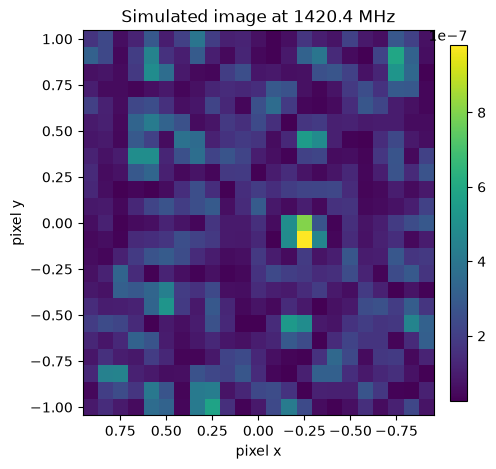

In [8]:
# Make and plot image
fwhm =  ((c.c/target_freq)/(largest_baseline)).decompose()*u.rad
sky_coverage = 2*u.rad
num_pix = int(sky_coverage / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

obs_num = 0

img, extent = make_image(acm[:, :], num_pix, uv[obs_num, :, :, :], target_freq)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {target_freq:.1f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


Output()

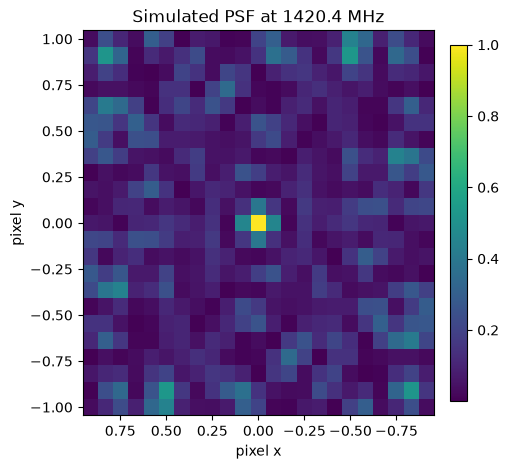

In [9]:
psf, psf_extent = make_image(np.ones_like(acm[:, :]), num_pix, uv[obs_num, :, :, :], target_freq)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im_psf = ax.imshow(psf, extent=psf_extent, origin='lower')

ax.set_title(f"Simulated PSF at {target_freq:.1f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im_psf, ax=ax, fraction=0.046, pad=0.04)
plt.show()